# How does INR uncertainty change with the NUMBER OF IMAGES, the network size and the noise?

One implicit neural representation `f(x, y, image id) -> (mean, log-variance)` is trained on **N images at once** (each image gets
a learned code vector; all images share the weights). Each image is a different synthetic picture from one family (blobs, a disc,
a stripe pattern, random positions and strengths) and is observed through 30% of its pixels with Gaussian noise. Three knobs,
each from **1 to 100**:

| Knob | Meaning of 1 ... 100 |
|---|---|
| **n**: number of images | how many images the one network must represent (images 0..n-1; image 0 is always included) |
| **width**: network size | hidden-layer width, 1 to 100 units (3 hidden layers, Fourier-feature input) |
| **noise**: observation noise | noise standard deviation as a percent of the images' own standard deviation |

**Uncertainty measures** (M seeds per setting): `A` = mean predicted variance (aleatoric: should track the noise variance),
`E` = variance of the predicted means across seeds (epistemic: model disagreement). The truth is known, so we also record the
**true error** and whether the uncertainty tracks it. Uncertainty is evaluated at random off-grid points of up to 10 of the images
(`E`, `err`, ... = average over those images); `E0`, `err0` are for **image 0 only**, which is in every run, so it is the strictly
comparable curve as n grows. A block in the middle of every image never has training pixels.

**GPU.** If PyTorch can see an NVIDIA GPU the notebook uses it automatically (the device is printed in the settings cell). On Windows a plain
`pip install torch` often installs the CPU-only build; for the GPU build run once in a terminal:
`pip install torch --index-url https://download.pytorch.org/whl/cu124` (or pick your CUDA version at pytorch.org/get-started).

**Design.** A full 100 x 100 x 100 grid is a million trainings, so we do three **one-at-a-time sweeps** and three **pairwise
heatmaps**. The cell after the settings **benchmarks your machine and prints the projected run time** before anything long starts.

In [1]:
import sys, os, math, time, json, pickle, subprocess, warnings
warnings.filterwarnings("ignore")
try:
    import torch
except ImportError:                                   # e.g. a fresh Colab / venv
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch"])
    import torch
import torch.nn as nn
import numpy as np
from scipy.stats import spearmanr
from scipy.spatial import cKDTree
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

## 1. Settings (edit here)

In [2]:
QUICK = False                       # set True for a 1-2 minute smoke test (smaller everything)
G = 32                               # each image is G x G pixels
PIX_FRAC = 0.30                      # fraction of each image's pixels that is observed
M = 5                                # ensemble size (seeds) per setting
STEPS = 1000                         # optimisation steps per model
K_SWEEP = 12                         # values per one-at-a-time sweep (use 100 to try EVERY integer 1..100)
K_PAIR = 5                           # values per axis in the pairwise heatmaps
BASE = dict(n=10, width=50, noise=10)    # the held-fixed values when another knob is varied
N_EVAL = 10                          # evaluate on (up to) this many of the images
DIVERSITY = 1.0                      # 0 = all images identical, 1 = default variety, 2 = very different images
N_QUERY = 3000                       # random query points per image
EMB = 8                              # size of the learned per-image code
NFEAT, SCALE, WD, LAYERS = 32, 1.5, 1e-3, 3
SEED = 0
OUT = "results_images"
NTHREADS = int(os.environ.get("NTHREADS", os.cpu_count() or 1))
SHARD = None                         # command-line only: --shard i/k runs every k-th job (for parallel runs)
if "--shard" in sys.argv:
    SHARD = tuple(int(v) for v in sys.argv[sys.argv.index("--shard") + 1].split("/"))
if QUICK:
    G, M, STEPS, K_SWEEP, K_PAIR, N_QUERY, OUT = 20, 3, 300, 4, 3, 600, "results_images_quick"
os.makedirs(os.path.join(OUT, "cells"), exist_ok=True)
torch.set_num_threads(NTHREADS)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")      # uses your NVIDIA GPU automatically if PyTorch can see it
print(f"G={G} M={M} steps={STEPS} K_SWEEP={K_SWEEP} K_PAIR={K_PAIR} diversity={DIVERSITY} threads={NTHREADS} quick={QUICK} device={DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

G=32 M=5 steps=1000 K_SWEEP=12 K_PAIR=5 diversity=1.0 threads=2 quick=False device=cpu


## 2. The world: 100 synthetic images with known clean values everywhere

In [3]:
NMAX = 100


def image_fn(X, k):
    """Clean image number k on [0,1]^2 (analytic, so it can be evaluated at any coordinate). Image k is always the same."""
    r, D = np.random.default_rng(100 + k), DIVERSITY
    j = lambda s: D * r.uniform(-s, s)
    x0, x1 = X[:, 0], X[:, 1]
    f = 0.35 + (0.25 + j(0.15)) * x0 - (0.10 + j(0.15)) * x1
    f = f + (0.30 + j(0.10)) * np.exp(-(((x0 - 0.30 - j(0.12)) ** 2 + (x1 - 0.35 - j(0.12)) ** 2) / (0.020 * (1 + j(0.3)))))
    f = f + (0.25 + j(0.10)) * (((x0 - 0.70 - j(0.10)) ** 2 + (x1 - 0.65 - j(0.10)) ** 2) < 0.035)
    f = f + 0.08 * np.sin(2 * np.pi * (5 + round(j(1.5))) * x0 + j(1.5)) * np.sin(2 * np.pi * (4 + round(j(1.5))) * x1 + j(1.5))
    return f.astype(np.float32)


def in_hole(X):
    """A block in the middle that never has training samples (in every image)."""
    return (np.abs(X[:, 0] - 0.5) < 0.12) & (np.abs(X[:, 1] - 0.5) < 0.12)


c = (np.arange(G) + 0.5) / G
GRID = np.stack(np.meshgrid(c, c, indexing="xy"), -1).reshape(-1, 2).astype(np.float32)
OK = np.where(~in_hole(GRID))[0]
NPER = int(round(PIX_FRAC * len(OK)))                            # observed pixels per image
CLEAN = np.stack([image_fn(GRID, k) for k in range(NMAX)])       # (100, G*G)
STD_CLEAN = float(CLEAN.std(axis=1).mean())                      # 100% noise = as large as a typical image's own std
OBS = [np.random.default_rng(SEED + 10 + k).permutation(OK)[:NPER] for k in range(NMAX)]   # observed pixels of image k (fixed)
EPS = np.random.default_rng(SEED + 1).normal(size=CLEAN.shape).astype(np.float32)           # one fixed noise draw per pixel
XQ = np.random.default_rng(SEED + 2).random((N_QUERY, 2)).astype(np.float32)
HQ = in_hole(XQ)
FQ = np.stack([image_fn(XQ, k) for k in range(NMAX)])
print(f"{NMAX} images, {len(OK)} usable pixels each, {NPER} observed per image, image std {STD_CLEAN:.3f}")


def n_points(n): return n * NPER

100 images, 960 usable pixels each, 288 observed per image, image std 0.135


## 3. The INR and one training run

In [4]:
class INR(nn.Module):
    def __init__(self, width, seed, n_img):
        super().__init__()
        g = torch.Generator().manual_seed(1000 + seed)
        self.register_buffer("B", torch.randn(2, NFEAT, generator=g) * SCALE)
        torch.manual_seed(seed)
        self.emb = nn.Embedding(n_img, EMB); nn.init.normal_(self.emb.weight, std=0.3)
        layers, d = [], 2 * NFEAT + EMB
        for _ in range(LAYERS):
            layers += [nn.Linear(d, width), nn.ReLU()]; d = width
        self.net = nn.Sequential(*layers, nn.Linear(d, 2))

    def forward(self, x, img):
        z = 2 * math.pi * x @ self.B
        o = self.net(torch.cat([torch.sin(z), torch.cos(z), self.emb(img)], -1))
        return o[:, 0], -10.0 + 10.0 * torch.sigmoid(o[:, 1])          # mean, log-variance in (-10, 0)


def fit(width, seed, n_img, xt, it, yt):
    m = INR(width, seed, n_img).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=2e-3, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, STEPS)
    warm = int(0.25 * STEPS)
    for t in range(STEPS):
        mu, lv = m(xt, it)
        loss = ((mu - yt) ** 2).mean() if t < warm else (0.5 * (lv + (mu - yt) ** 2 * torch.exp(-lv))).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return m


def make_data(n, sigma):
    xs = np.concatenate([GRID[OBS[k]] for k in range(n)])
    ids = np.concatenate([np.full(NPER, k) for k in range(n)])
    ys = np.concatenate([CLEAN[k][OBS[k]] + sigma * EPS[k][OBS[k]] for k in range(n)])
    return torch.tensor(xs).to(DEVICE), torch.tensor(ids).to(DEVICE), torch.tensor(ys.astype(np.float32)).to(DEVICE)

## 4. One setting (n images, width, noise): train M seeds, split the uncertainty, compare with the truth

In [5]:
def rho(a, b, mask):
    a, b = a[mask], b[mask]
    return float(spearmanr(a, b)[0]) if len(a) > 5 and np.std(a) > 0 and np.std(b) > 0 else float("nan")


def run_cell(n, width, noise):
    sigma = noise / 100 * STD_CLEAN
    xt, it, yt = make_data(n, sigma)
    ev = list(range(min(n, N_EVAL)))
    xq = torch.tensor(np.tile(XQ, (len(ev), 1))).to(DEVICE); iq = torch.tensor(np.repeat(ev, len(XQ))).to(DEVICE)
    mus, vs, trr = [], [], []
    for s in range(M):
        m = fit(width, s, n, xt, it, yt)
        with torch.no_grad():
            mu, lv = m(xq, iq); trr.append(float(((m(xt, it)[0] - yt) ** 2).mean() ** 0.5))
        mus.append(mu.cpu().numpy().reshape(len(ev), -1)); vs.append(torch.exp(lv).cpu().numpy().reshape(len(ev), -1))
    mus, vs = np.stack(mus), np.stack(vs)                              # (M, images, queries)
    mu, A, E = mus.mean(0), vs.mean(0), mus.var(0, ddof=1)
    tot, err, out = A + E, np.abs(mu - FQ[ev]), ~HQ
    per = lambda f: float(np.mean([f(i) for i in range(len(ev))]))
    S = cKDTree(GRID[OBS[0]]).query(XQ, k=1)[0]
    return dict(n=n, width=width, noise=noise, n_train=n_points(n), sigma=sigma,
                A=per(lambda i: np.median(A[i][out])), E=per(lambda i: np.median(E[i][out])), tot=per(lambda i: np.median(tot[i][out])),
                A_hole=per(lambda i: np.median(A[i][HQ])), E_hole=per(lambda i: np.median(E[i][HQ])),
                err=per(lambda i: np.median(err[i][out])), err_hole=per(lambda i: np.median(err[i][HQ])),
                rmse=per(lambda i: np.sqrt(np.mean(err[i][out] ** 2))),
                rho_std_err=per(lambda i: rho(np.sqrt(tot[i]), err[i], out)), rho_std_err_hole=per(lambda i: rho(np.sqrt(tot[i]), err[i], HQ)),
                share_E=per(lambda i: np.median(E[i][out] / tot[i][out])),
                E0=float(np.median(E[0][out])), A0=float(np.median(A[0][out])), err0=float(np.median(err[0][out])),
                err0_hole=float(np.median(err[0][HQ])), E0_hole=float(np.median(E[0][HQ])), rho0=rho(np.sqrt(tot[0]), err[0], out),
                train_rmse=float(np.mean(trr)), S=float(np.median(S)))

## 5. The list of settings to run, and a time estimate for YOUR machine
`grid(K)` gives K values from 1 to 100 (log-spaced, so the small end is covered densely); `K=100` means every integer.

In [6]:
def grid(K):
    return np.arange(1, 101) if K >= 100 else np.unique(np.round(np.geomspace(1, 100, K)).astype(int))


def key(n, w, s): return (int(n), int(w), int(s))


JOBS = {}
for knob in ("n", "width", "noise"):                                     # one-at-a-time sweeps
    for v in grid(K_SWEEP):
        p = dict(BASE); p[knob] = int(v); JOBS[key(p["n"], p["width"], p["noise"])] = p
for a_, b_ in (("n", "noise"), ("n", "width"), ("width", "noise")):       # pairwise heatmaps
    for va in grid(K_PAIR):
        for vb in grid(K_PAIR):
            p = dict(BASE); p[a_] = int(va); p[b_] = int(vb); JOBS[key(p["n"], p["width"], p["noise"])] = p
JOB_LIST = list(JOBS.values())
if SHARD:
    JOB_LIST = JOB_LIST[SHARD[0]::SHARD[1]]


def cell_file(k): return os.path.join(OUT, "cells", f"n{k[0]}_w{k[1]}_s{k[2]}.pkl")


def estimate_minutes(jobs):
    """Time a few real trainings on this machine, fit  time ~ a + b*n*width^2 + c*n  (non-negative), add up the pending jobs."""
    from scipy.optimize import nnls
    fit(4, 0, 2, *make_data(2, 0.1))                                                          # warm-up, not timed
    pts = [(2, 4), (2, 100), (50, 4), (50, 100), (15, 50)]                                    # (images, width)
    ts = []
    for nn_, w in pts:
        d = make_data(nn_, 0.1); t0 = time.time(); fit(w, 0, nn_, *d)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        ts.append(time.time() - t0)
    feat = lambda nt, w: [1.0, nt * w * w / 1e6, nt / 1e3]
    pts = [(nn_ * NPER, w) for nn_, w in pts]
    coef = nnls(np.array([feat(nt, w) for nt, w in pts]), np.array(ts))[0]
    pending = [j for j in jobs if not os.path.exists(cell_file(key(j["n"], j["width"], j["noise"])))]
    cost = lambda js: sum(float(coef @ feat(n_points(j["n"]), j["width"])) * M for j in js) / 60
    return cost(jobs), cost(pending), len(pending), dict(zip([f"n={nt},w={w}" for nt, w in pts], [f"{t:.1f}s" for t in ts]))


est_all, est, npend, bench = estimate_minutes(JOB_LIST)
print(f"{len(JOBS)} distinct settings in total, {npend} still to run (x {M} seeds = {npend * M} trainings)")
print("benchmark, one training each:", bench)
print(f"==> projected time for the FULL grid on this machine: about {est_all:.0f} minutes (rough range {0.6 * est_all:.0f}-{1.6 * est_all:.0f})")
print(f"==> for the {npend} settings still to run: about {est:.0f} minutes; results are cached, so you can stop and resume")

if "--estimate-only" in sys.argv:
    sys.exit(0)

97 distinct settings in total, 0 still to run (x 5 seeds = 0 trainings)
benchmark, one training each: {'n=576,w=4': '2.0s', 'n=576,w=100': '3.8s', 'n=14400,w=4': '8.5s', 'n=14400,w=100': '38.1s', 'n=4320,w=50': '7.5s'}
==> projected time for the FULL grid on this machine: about 64 minutes (rough range 38-102)
==> for the 0 settings still to run: about 0 minutes; results are cached, so you can stop and resume


## 6. Run everything (each setting is saved to disk as soon as it finishes)

In [7]:
t_all, done = time.time(), 0
for j in JOB_LIST:
    k = key(j["n"], j["width"], j["noise"])
    if os.path.exists(cell_file(k)):
        continue
    r = run_cell(**j); pickle.dump(r, open(cell_file(k), "wb")); done += 1
    if done % 10 == 0 or done == npend:
        print(f"  {done}/{npend} settings done, {time.time() - t_all:.0f}s elapsed", flush=True)
if SHARD or "--compute-only" in sys.argv:
    sys.exit(0)
RES = {k: pickle.load(open(cell_file(k), "rb")) for k in JOBS}
print(f"loaded {len(RES)} settings; actual compute time this session: {time.time() - t_all:.0f}s")

loaded 97 settings; actual compute time this session: 0s


## 7. One-at-a-time sweeps: how does each knob change the uncertainty?
Rows: (1) the two uncertainties (E solid, A dashed; the true noise variance is the dotted line in the noise column),
(2) the true error, (3) does the uncertainty track the error (rank correlation), (4) training error relative to the noise
level (below 1 = the model is fitting the noise).

   knob  value  n_train          E          A  true noise var  |error|    rho
      n      1      288   1.23e-04   4.62e-05        1.83e-04    0.011   0.45
      n      2      576   2.68e-04   4.83e-05        1.83e-04    0.013   0.44
      n      4     1152   3.95e-04   4.93e-05        1.83e-04    0.016   0.40
      n      5     1440   4.51e-04   5.18e-05        1.83e-04    0.016   0.41
      n      8     2304   5.40e-04   1.09e-04        1.83e-04    0.018   0.42
      n     12     3456   6.12e-04   2.60e-04        1.83e-04    0.020   0.40
      n     19     5472   7.02e-04   5.14e-04        1.83e-04    0.023   0.38
      n     28     8064   6.53e-04   8.33e-04        1.83e-04    0.025   0.34
      n     43    12384   5.71e-04   1.17e-03        1.83e-04    0.026   0.27
      n     66    19008   4.87e-04   1.35e-03        1.83e-04    0.029   0.29
      n    100    28800   3.89e-04   1.56e-03        1.83e-04    0.031   0.28

  width      1     2880   1.59e-02   1.29e-02        1.83e-04  

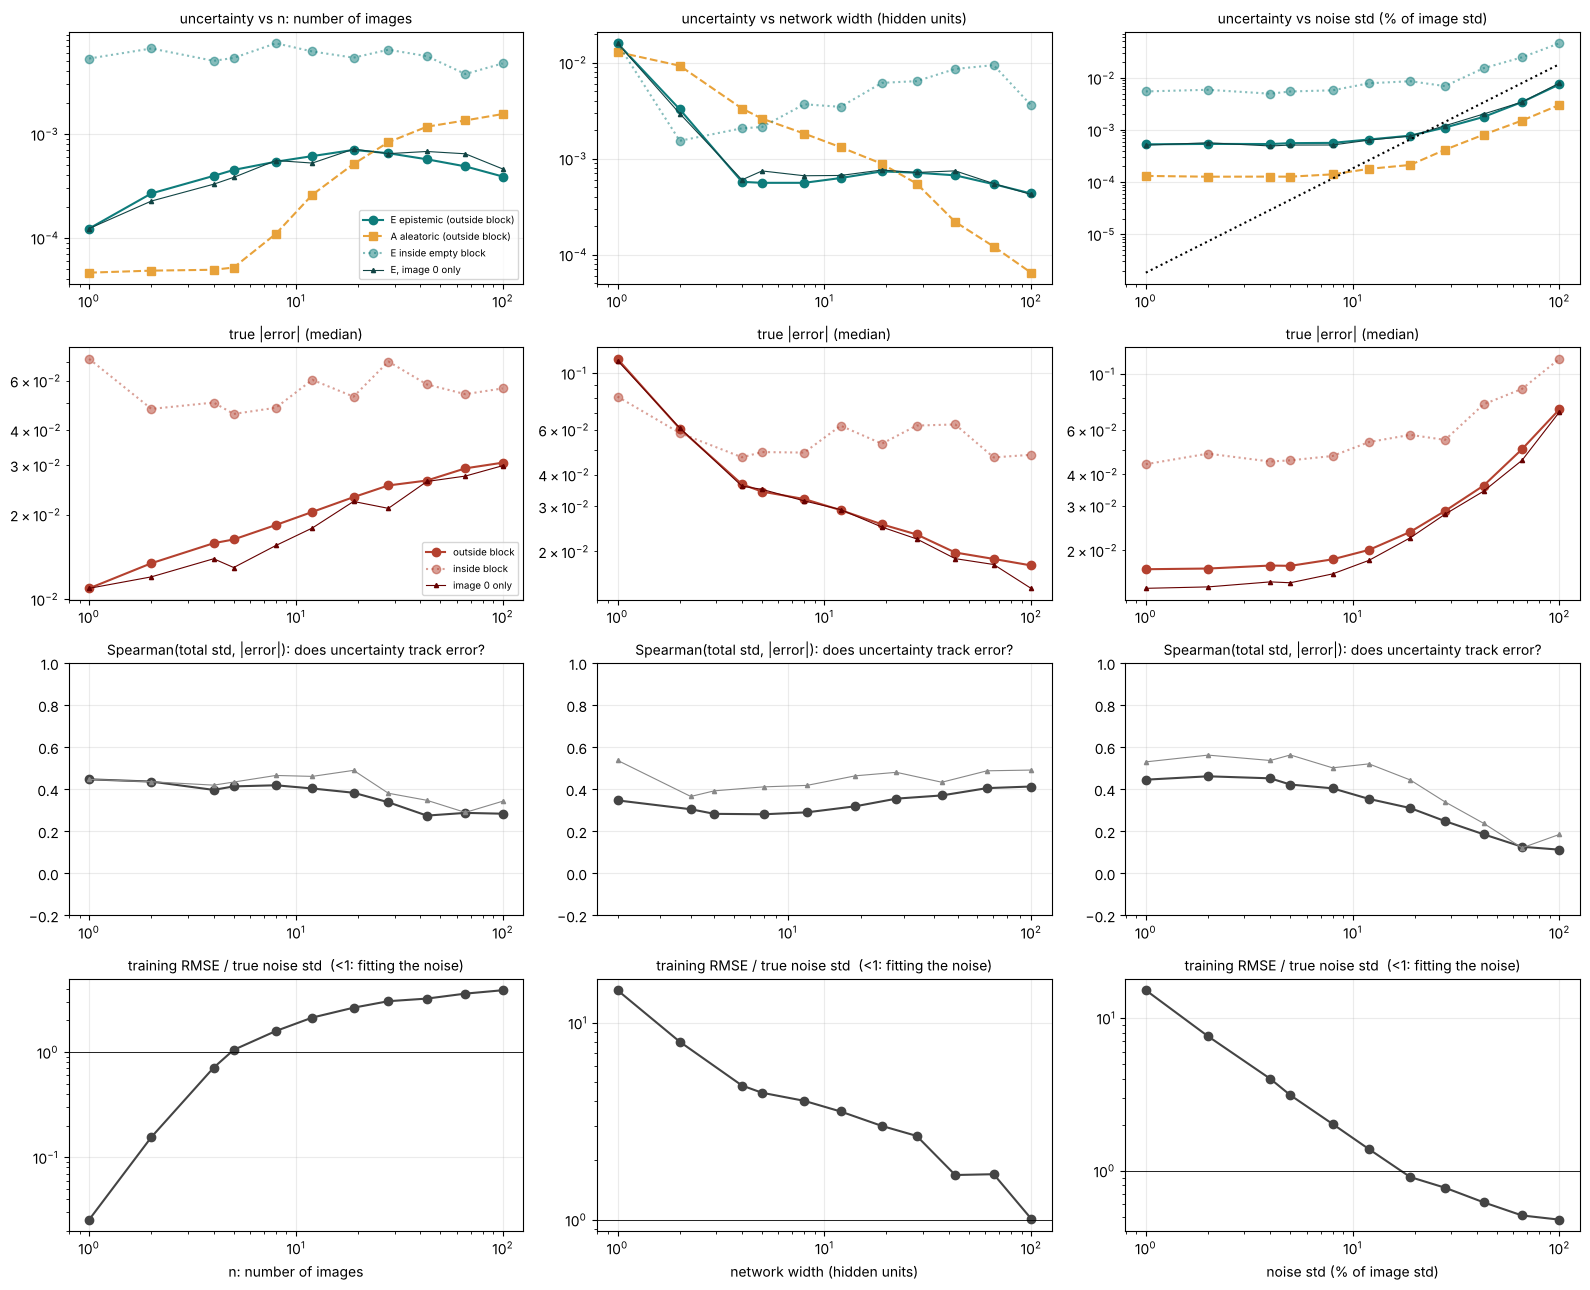

In [8]:
knobs = [("n", "n: number of images"),
         ("width", "network width (hidden units)"), ("noise", "noise std (% of image std)")]
colE, colA, colX = "#0E7C7B", "#E8A23A", "#B4412F"


def line(knob):
    vs_ = sorted(grid(K_SWEEP).tolist())
    rows = [RES[key(*[(v if k_ == knob else BASE[k_]) for k_ in ("n", "width", "noise")])] for v in vs_]
    return vs_, rows


fig, ax = plt.subplots(4, 3, figsize=(16, 13))
for ci, (knob, label) in enumerate(knobs):
    xs, rows = line(knob)
    g = lambda k_: np.array([r[k_] for r in rows])
    a = ax[0, ci]
    a.plot(xs, g("E"), "o-", color=colE, label="E epistemic (outside block)"); a.plot(xs, g("A"), "s--", color=colA, label="A aleatoric (outside block)")
    a.plot(xs, g("E_hole"), "o:", color=colE, alpha=.5, label="E inside empty block")
    a.plot(xs, g("E0"), "^-", color="#144", ms=3, lw=.8, label="E, image 0 only")
    if knob == "noise": a.plot(xs, g("sigma") ** 2, ":", color="k", label="TRUE noise variance")
    a.set_yscale("log"); a.set_xscale("log"); a.set_title(f"uncertainty vs {label}", fontsize=10); a.grid(alpha=.25)
    if ci == 0: a.legend(fontsize=7)
    a = ax[1, ci]; a.plot(xs, g("err"), "o-", color=colX, label="outside block"); a.plot(xs, g("err_hole"), "o:", color=colX, alpha=.5, label="inside block"); a.plot(xs, g("err0"), "^-", color="#600", ms=3, lw=.8, label="image 0 only")
    a.set_yscale("log"); a.set_xscale("log"); a.set_title("true |error| (median)", fontsize=10); a.grid(alpha=.25)
    if ci == 0: a.legend(fontsize=7)
    a = ax[2, ci]; a.plot(xs, g("rho_std_err"), "o-", color="#444"); a.plot(xs, g("rho0"), "^-", color="#888", ms=3, lw=.8); a.set_xscale("log"); a.set_ylim(-0.2, 1)
    a.set_title("Spearman(total std, |error|): does uncertainty track error?", fontsize=10); a.grid(alpha=.25)
    a = ax[3, ci]; a.plot(xs, g("train_rmse") / g("sigma"), "o-", color="#444"); a.axhline(1, color="k", lw=.6)
    a.set_yscale("log"); a.set_xscale("log"); a.set_xlabel(label); a.set_title("training RMSE / true noise std  (<1: fitting the noise)", fontsize=10); a.grid(alpha=.25)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "sweeps_one_at_a_time.png"), dpi=120)

print(f"{'knob':>7s}{'value':>7s}{'n_train':>9s}{'E':>11s}{'A':>11s}{'true noise var':>16s}{'|error|':>9s}{'rho':>7s}")
for knob, _ in knobs:
    xs, rows = line(knob)
    for v, r in list(zip(xs, rows))[:: max(1, len(xs) // 8)]:
        print(f"{knob:>7s}{v:>7d}{r['n_train']:>9d}{r['E']:>11.2e}{r['A']:>11.2e}{r['sigma'] ** 2:>16.2e}{r['err']:>9.3f}{r['rho_std_err']:>7.2f}")
    print()

## 8. Pairwise heatmaps: interactions between the knobs
Rows: log10 of the epistemic E, log10 of A divided by the TRUE noise variance (0 = the aleatoric estimate is right; below 0 =
underestimated, i.e. the model is absorbing the noise), and log10 of the true error. The third knob is held at its baseline.

saved figures and all_settings.json to results_images


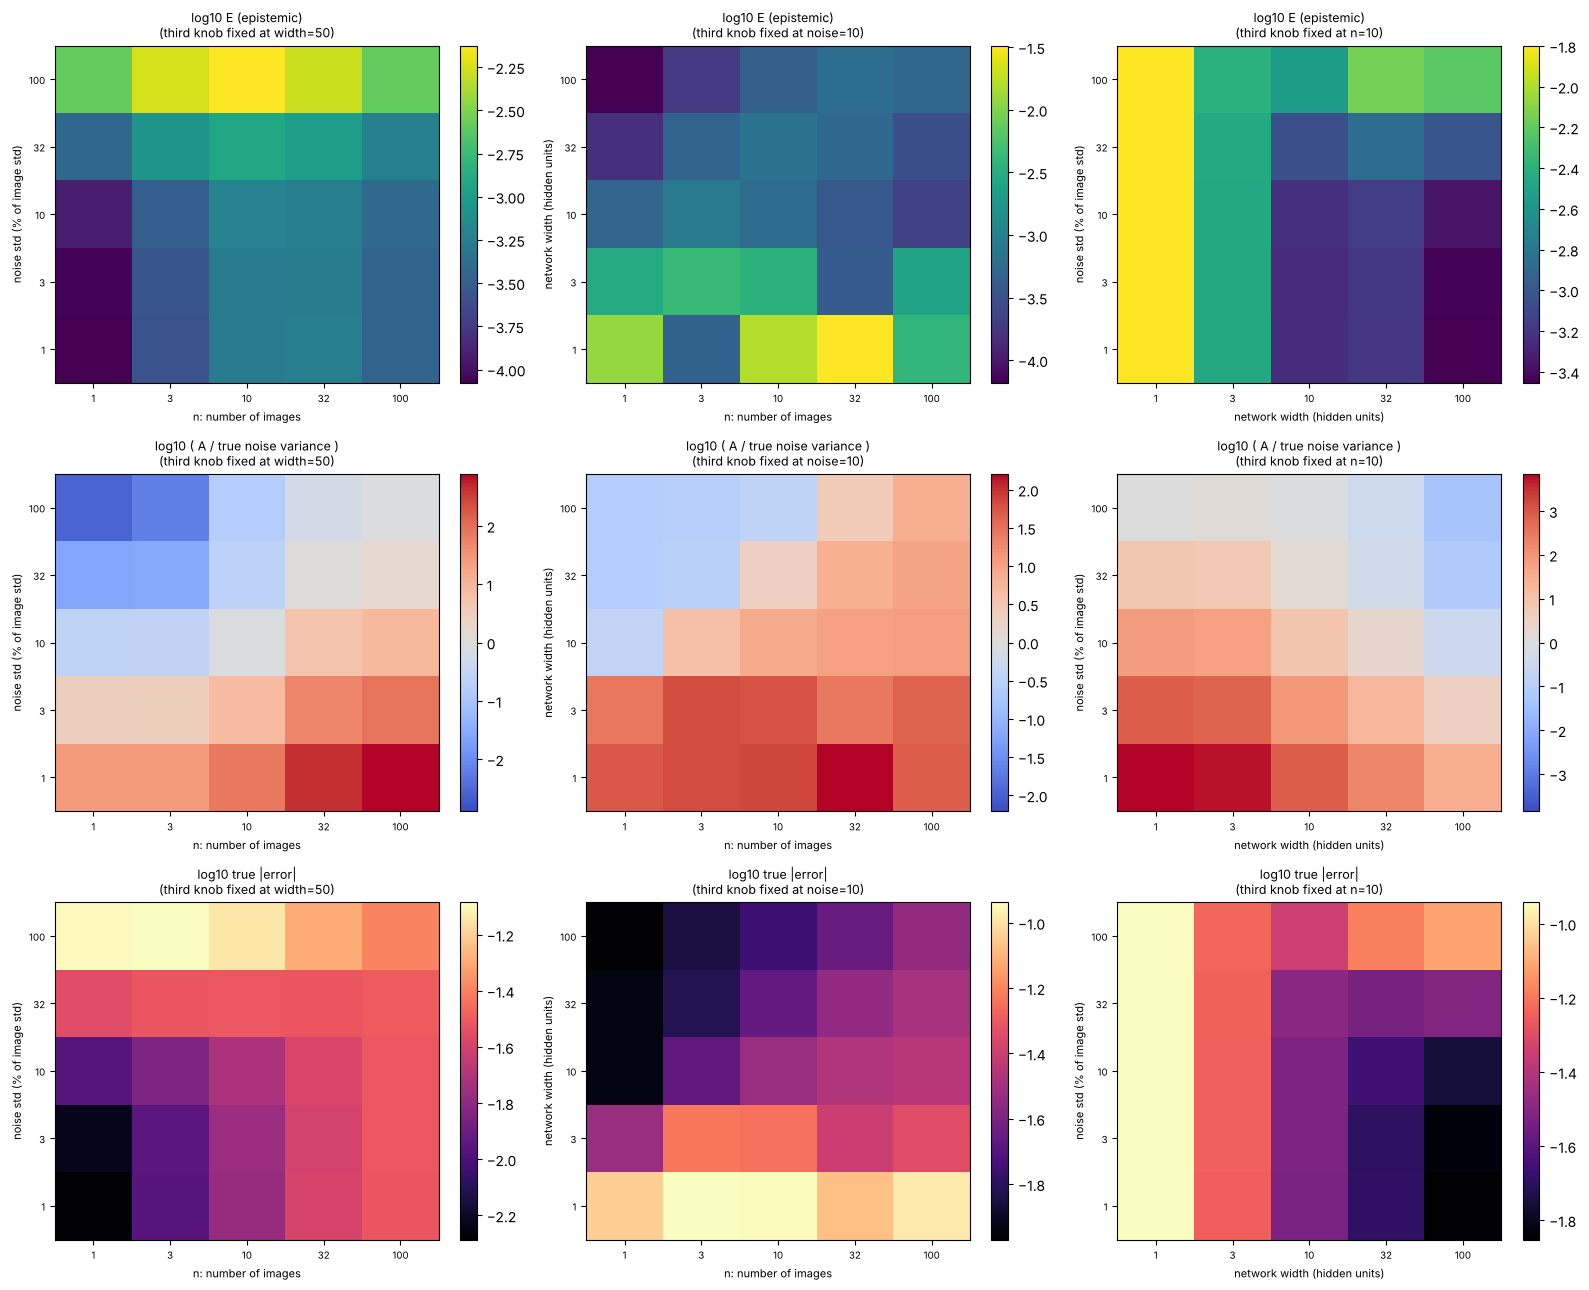

In [9]:
pairs = [("n", "noise"), ("n", "width"), ("width", "noise")]
lab = dict(knobs)
vals = sorted(grid(K_PAIR).tolist())
fig, ax = plt.subplots(3, 3, figsize=(16, 13))
for ci, (a_, b_) in enumerate(pairs):
    def cellv(i, j, k_):
        p = dict(BASE); p[a_] = vals[j]; p[b_] = vals[i]
        return RES[key(p["n"], p["width"], p["noise"])][k_]
    mats = [np.log10([[cellv(i, j, "E") for j in range(len(vals))] for i in range(len(vals))]),
            np.log10([[cellv(i, j, "A") / max(cellv(i, j, "sigma") ** 2, 1e-12) for j in range(len(vals))] for i in range(len(vals))]),
            np.log10([[cellv(i, j, "err") for j in range(len(vals))] for i in range(len(vals))])]
    for ri, (mat, title, cmap) in enumerate(zip(mats, ["log10 E (epistemic)", "log10 ( A / true noise variance )", "log10 true |error|"],
                                                  ["viridis", "coolwarm", "magma"])):
        a = ax[ri, ci]
        kw = dict(vmin=-max(abs(np.nanmin(mat)), abs(np.nanmax(mat))), vmax=max(abs(np.nanmin(mat)), abs(np.nanmax(mat)))) if ri == 1 else {}
        im = a.imshow(mat, origin="lower", cmap=cmap, aspect="auto", **kw); plt.colorbar(im, ax=a, fraction=0.046)
        a.set_xticks(range(len(vals))); a.set_xticklabels(vals, fontsize=7); a.set_yticks(range(len(vals))); a.set_yticklabels(vals, fontsize=7)
        a.set_xlabel(lab[a_], fontsize=8); a.set_ylabel(lab[b_], fontsize=8)
        a.set_title(f"{title}\n(third knob fixed at {[k_ for k_ in BASE if k_ not in (a_, b_)][0]}={BASE[[k_ for k_ in BASE if k_ not in (a_, b_)][0]]})", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "heatmaps_pairs.png"), dpi=120)
json.dump({f"n{k[0]}_w{k[1]}_s{k[2]}": v for k, v in RES.items()}, open(os.path.join(OUT, "all_settings.json"), "w"), indent=1)
print("saved figures and all_settings.json to", OUT)